In [ ]:
import os
import pandas as pd

# Set the path to the directory containing the selected dataset
path = '/content'

# List the files in the downloaded dataset path
files = os.listdir(path)
print('Files in dataset directory:', files)

Files in dataset directory: ['.config', '.ipynb_checkpoints', '5g_network_traffic_anomalies (1).csv', 'sample_data']


In [ ]:
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f'Successfully loaded {csv_files[0]}')
    display(df.head())
else:
    print('No CSV files found in the dataset directory.')

Successfully loaded 5g_network_traffic_anomalies (1).csv


,timestamp,active_ues,prb_usage_pct,throughput_mbps,latency_ms,packet_loss_pct,rsrp_dbm,sinr_db,slice_bandwidth_gbps,is_weekend,is_anomaly,anomaly_type
0,2026-03-01 00:00:00,206,31.05,777.44,6.66,0.0140,-82.65,22.28,1.70,1,0,normal
1,2026-03-01 00:05:00,192,33.54,815.62,8.11,0.0328,-84.48,17.98,1.62,1,0,normal
2,2026-03-01 00:10:00,207,30.12,818.63,7.01,0.0903,-89.93,18.74,2.03,1,0,normal
3,2026-03-01 00:15:00,223,32.34,839.95,8.20,0.0286,-82.42,17.01,1.77,1,0,normal
4,2026-03-01 00:20:00,187,24.19,758.11,8.34,0.0408,-74.22,20.28,1.60,1,0,normal


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split

target_col = 'is_anomaly'

# Split data (dropping non-numeric text columns to avoid sklearn errors)
X = df.drop(columns=[target_col, 'timestamp', 'anomaly_type'])
y = df[target_col]

# Splitting into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Target class unique values: {y.unique()}")
print(f"Configuring baseline to always predict negative class: {0}")

# Build a baseline that always predicts the negative class
dummy_clf = DummyClassifier(strategy='constant', constant=0)
dummy_clf.fit(X_train, y_train)

# Evaluate
y_pred = dummy_clf.predict(X_test)
print("\nEvaluation Metrics for Always-Negative Baseline Classifier:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Target class unique values: [0 1]
Configuring baseline to always predict negative class: 0

Evaluation Metrics for Always-Negative Baseline Classifier:
Accuracy: 0.9075

Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95       363
           1       0.00      0.00      0.00        37

    accuracy                           0.91       400
   macro avg       0.45      0.50      0.48       400
weighted avg       0.82      0.91      0.86       400



In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split

target_col = 'is_anomaly'

# Split data (dropping non-numeric text columns to avoid sklearn errors)
X = df.drop(columns=[target_col, 'timestamp', 'anomaly_type'])
y = df[target_col]

# Splitting into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Target class unique values: {y.unique()}")
print(f"Configuring baseline to always predict negative class: {0}")

# Build a baseline that always predicts the negative class
dummy_clf = DummyClassifier(strategy='constant', constant=0)
dummy_clf.fit(X_train, y_train)

# Evaluate
y_pred = dummy_clf.predict(X_test)
print("\nEvaluation Metrics for Always-Negative Baseline Classifier:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Target class unique values: [0 1]
Configuring baseline to always predict negative class: 0

Evaluation Metrics for Always-Negative Baseline Classifier:
Accuracy: 0.9075

Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95       363
           1       0.00      0.00      0.00        37

    accuracy                           0.91       400
   macro avg       0.45      0.50      0.48       400
weighted avg       0.82      0.91      0.86       400



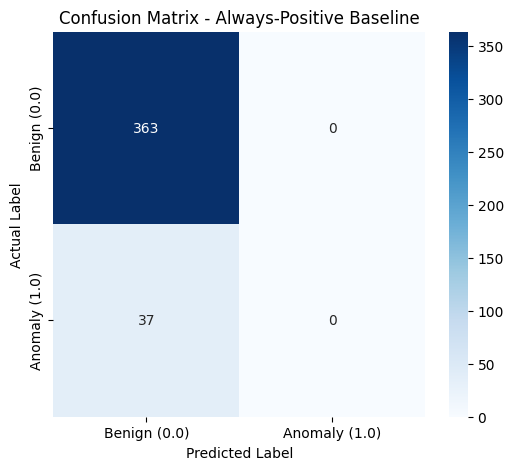

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0.0, 1.0])

# Plot heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign (0.0)', 'Anomaly (1.0)'],
            yticklabels=['Benign (0.0)', 'Anomaly (1.0)'])
plt.title('Confusion Matrix - Always-Positive Baseline')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


# feature engineering
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_balanced = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = lr_balanced.predict(X_test_scaled)

print("Evaluation Metrics for Balanced Logistic Regression Model:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_balanced):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced, zero_division=0))

Evaluation Metrics for Balanced Logistic Regression Model:
Accuracy: 0.9500

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.97       363
           1       0.67      0.89      0.77        37

    accuracy                           0.95       400
   macro avg       0.83      0.92      0.87       400
weighted avg       0.96      0.95      0.95       400



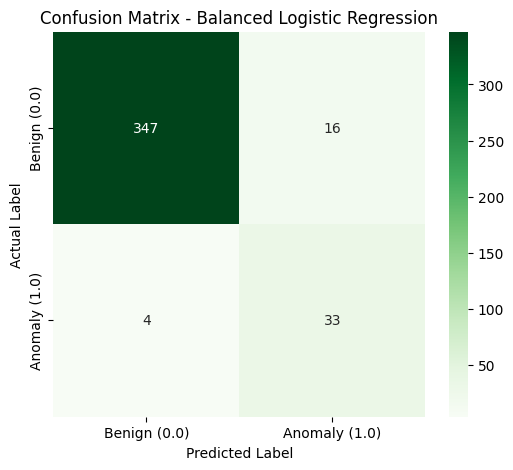

In [ ]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced, labels=[0.0, 1.0])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_balanced, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Benign (0.0)', 'Anomaly (1.0)'],
            yticklabels=['Benign (0.0)', 'Anomaly (1.0)'])
plt.title('Confusion Matrix - Balanced Logistic Regression')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()